<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/01-que-es-machine-learning/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 1.1 · ¿Qué es Machine Learning?

**Serie:** Del Excel al Machine Learning · **Temporada 1** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- La diferencia entre **escribir una regla** y **aprender de ejemplos**.
- Qué son las variables de entrada, el objetivo, entrenar y predecir.
- Crear tu primer modelo con **scikit-learn**, en tres líneas.
- Distinguir cuándo basta una regla y cuándo conviene un modelo.

## 📊 En Excel lo harías así

El descuento de Distribuidora Andina tiene una regla exacta: 5 % desde 10 presentaciones y 10 % desde 20. En Excel escribes:

`=SI(A2>=20, 10%, SI(A2>=10, 5%, 0))`

Tú le das la regla, y Excel la aplica. Pero ¿qué fórmula escribes para saber **cuánto comprará un cliente el próximo mes**? Ninguna: nadie conoce esa regla.

## 🐍 En Python

### Paso 1: cuando sí hay una regla

Empezamos por las librerías. **scikit-learn** es la herramienta de Python para Machine Learning, y Colab ya la trae. De ella traemos `LinearRegression`, que usaremos en el Paso 3.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

La regla del descuento se escribe con el `if` del episodio 0.3. `.apply()` la aplica a toda la columna, como arrastrar una fórmula. Luego contamos cuántas filas no coinciden con el dato real:

In [2]:
ventas = pd.read_csv(DATOS + "ventas.csv")
productos = pd.read_csv(DATOS + "productos.csv")


def descuento(cantidad):
    if cantidad >= 20:
        return 0.10
    elif cantidad >= 10:
        return 0.05
    else:
        return 0


calculado = ventas["cantidad"].apply(descuento)

print((calculado != ventas["descuento"]).sum())

0


Cero errores en 50,000 filas. Si conoces la regla, **escríbela**. No necesitas Machine Learning.

### Paso 2: cuando nadie conoce la regla

Mira las compras de un cliente, mes a mes. `.str[:7]` toma los primeros 7 caracteres de la fecha, como `=IZQUIERDA()` (`LEFT`), y deja el año y el mes:

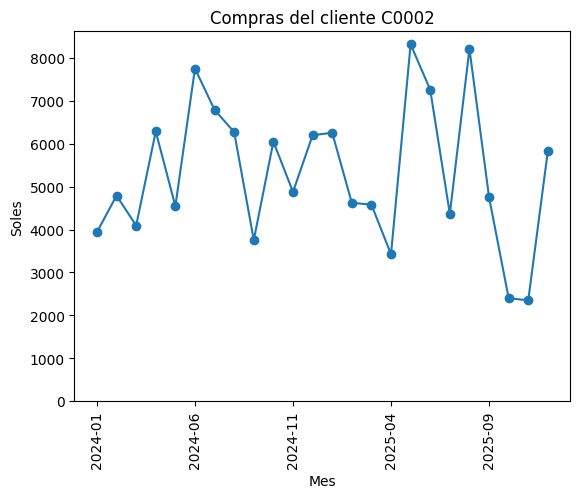

In [3]:
cliente = ventas[ventas["id_cliente"] == "C0002"]
por_mes = cliente.groupby(cliente["fecha"].str[:7])["total"].sum()

por_mes.plot(
    kind="line",
    marker="o",
    title="Compras del cliente C0002",
    xlabel="Mes",
    ylabel="Soles",
    rot=90,
    ylim=(0, None),
)
plt.show()

Sube y baja, y no hay una fórmula exacta. Lo que sí tenemos es **historia**. Y esa es la idea de Machine Learning:

> En lugar de escribir la regla, le damos **ejemplos** a la computadora, y ella busca el patrón.

Es como un vendedor nuevo. Nadie le da una fórmula: después de ver muchos pedidos, aprende a calcular cuánto llevará cada cliente.

Son cuatro palabras:

| Palabra | Qué significa | En un Excel |
|---|---|---|
| **Variables de entrada** | Lo que ya sabes | Las columnas que usas para calcular |
| **Objetivo** | Lo que quieres predecir | La columna del resultado |
| **Entrenar** | Buscar el patrón en los ejemplos | Ajustar una fórmula hasta que calce |
| **Predecir** | Usar el patrón en un caso nuevo | Aplicar la fórmula a otra fila |

### Paso 3: tu primer modelo

Hagamos una prueba donde podamos comprobar el resultado. Tomamos las ventas de un producto, sin descuento, y **no le decimos el precio** al modelo. ¿Podrá descubrirlo solo?

In [4]:
chicha = ventas[(ventas["id_producto"] == "P022") & (ventas["descuento"] == 0)]

chicha[["cantidad", "total"]].head()

,cantidad,total
0,3,144.0
28,3,144.0
31,2,96.0
39,2,96.0
56,3,144.0


Separamos los ejemplos, entrenamos y predecimos:

- `x` lleva las variables de entrada. Va con **doble corchete**, porque el modelo espera una tabla, aunque tenga una sola columna. Con un solo par, verás un `ValueError`.
- `y` lleva el objetivo.
- `.fit()` entrena: es el momento en que el modelo aprende.
- `.predict()` predice. También recibe una tabla, con el mismo nombre de columna, y por eso armamos una con `pd.DataFrame()`. Muchos tutoriales escriben `predict([[7]])`: funciona, pero da una advertencia porque no le pasaste el nombre.

In [5]:
x = chicha[["cantidad"]]
y = chicha["total"]

modelo = LinearRegression()
modelo.fit(x, y)

nuevo = pd.DataFrame({"cantidad": [7]})
print(modelo.predict(nuevo))

[336.]


Predijo el total de una venta de 7 presentaciones, aunque nadie le dio el precio. Lo que aprendió está en `.coef_`. Comparémoslo con el catálogo:

In [6]:
print(modelo.coef_.round(2))

productos[productos["id_producto"] == "P022"][["nombre", "precio"]]

[48.]


,nombre,precio
21,Chicha morada 1 L,48.0


¡El mismo precio! Lo descubrió mirando los ejemplos. Aquí acierta perfecto porque `total` sale de una fórmula exacta. Lo usamos para comprobar que el modelo aprende. **En la práctica, para esto usarías la fórmula.** El Machine Learning vale la pena cuando nadie conoce la regla, y ahí nunca acierta perfecto: eso empieza en el próximo episodio.

> ⚠️ Machine Learning no es magia ni reemplaza tu criterio. Encuentra patrones en los datos que le das: si los datos están mal, el patrón también.

## 🤖 Pídeselo a la IA

Pídele ejemplos de tu trabajo, sin datos reales:

> *"Trabajo en una oficina de compras. Dame tres tareas que se resuelven con una regla de Excel y tres en las que serviría Machine Learning. Explica por qué."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Tu propia regla con `=SI()` (`IF`) | `if` / `else` y `.apply()` |
| Las columnas que usas para calcular | `x = tabla[["columna"]]` |
| La columna del resultado | `y = tabla["columna"]` |
| Ajustar una fórmula a los datos | `modelo.fit(x, y)` |
| Aplicar la fórmula a una fila nueva | `modelo.predict(nuevo)` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/01-que-es-machine-learning/ejercicio.ipynb) y entrena tus primeros modelos. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/01-que-es-machine-learning/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0